# Telco Customer Churn Prediction: Data Cleaning, Statistical Summary, EDA & Logistic Regression

**Objective:** Predict customer churn (`Churn`: Yes/No) through a complete end-to-end workflow:
1. **Data Cleaning:** Inspect raw types, fix `TotalCharges` string formatting, handle missing values, and check duplicates.
2. **Descriptive Statistics (Mean, Median, Mode):** Compute central tendency and spread across numerical and categorical features.
3. **Exploratory Data Analysis (EDA) & Visuals:** Analyze churn drivers across contracts, internet services, tenure, and monthly charges using clear visualizations.
4. **Feature Engineering, Encoding & Scaling:** Build domain-specific telecom features (`NEW_TENURE_YEAR`, `NEW_Engaged`, `NEW_noProt`, `NEW_Young_Not_Engaged`, `NEW_TotalServices`, `NEW_FLAG_ANY_STREAMING`, `NEW_FLAG_AutoPayment`, `NEW_AVG_Charges`, `NEW_Increase`, `NEW_AVG_Service_Fee`), encode all non-numeric columns cleanly (compatible with Pandas 2.x & 3.x), and standardize features.
5. **Logistic Regression & Prediction Outputs:** Train baseline, class-balanced, and threshold-tuned Logistic Regression models, visualize ROC-AUC, Confusion Matrix, and Odds Ratios, and generate customer churn predictions.

## 1. Setup & Data Cleaning

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
import warnings
warnings.simplefilter(action="ignore")

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 170)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
sns.set_style("whitegrid")

# 1. Load Raw Dataset
df = pd.read_csv("Telco-Customer-Churn.csv")
print("Raw Dataset Shape:", df.shape)

# 2. Check & Remove Exact Duplicates
dup_count = df.duplicated().sum()
print(f"Exact Duplicate Rows: {dup_count}")
if dup_count > 0:
    df.drop_duplicates(inplace=True)

# 3. Clean TotalCharges (stored as string with 11 blank spaces where tenure == 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Impute missing TotalCharges with median
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# 4. Encode Target Variable: Yes -> 1, No -> 0
df["Churn"] = df["Churn"].apply(lambda x: 1 if str(x).strip() == "Yes" else 0)

print("\nMissing Values After Cleaning:", df.isnull().sum().sum())
print("Cleaned Dataset Shape:", df.shape)
df.head()

Raw Dataset Shape: (7043, 21)
Exact Duplicate Rows: 0

Missing Values Before Cleaning:
TotalCharges    11
dtype: int64

Missing Values After Cleaning: 0
Cleaned Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.850,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.500,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.750,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650,1


## 2. Descriptive Statistics: Mean, Median & Mode

In [9]:
# Separate numerical and categorical columns
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [col for col in df.columns if col not in num_cols + ["customerID"]]

# 1. Numerical Summary: Mean, Median, Mode, Std, Min, Max
num_stats = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Std_Dev": df[num_cols].std(),
    "Min": df[num_cols].min(),
    "Max": df[num_cols].max()
})
print("=== Numerical Features: Mean, Median, Mode & Spread ===")
print(num_stats.to_string())

# 2. Categorical Summary: Mode (Most Frequent Category) & Frequency %
cat_mode_rows = []
for col in cat_cols:
    mode_val = df[col].mode().iloc[0]
    mode_count = (df[col] == mode_val).sum()
    mode_pct = 100 * mode_count / len(df)
    cat_mode_rows.append({
        "Feature": col,
        "Unique_Values": df[col].nunique(),
        "Mode (Most Frequent)": mode_val,
        "Mode_Count": mode_count,
        "Mode_Share (%)": round(mode_pct, 2)
    })

cat_stats = pd.DataFrame(cat_mode_rows)
print("\n=== Categorical Features: Mode & Frequency Summary ===")
print(cat_stats.to_string(index=False))

=== Numerical Features: Mean, Median, Mode & Spread ===
                   Mean   Median   Mode  Std_Dev    Min      Max
tenure           32.371   29.000  1.000   24.559  0.000   72.000
MonthlyCharges   64.762   70.350 20.050   30.090 18.250  118.750
TotalCharges   2281.917 1397.475 20.200 2265.270 18.800 8684.800

=== Categorical Features: Mode & Frequency Summary ===
         Feature  Unique_Values Mode (Most Frequent)  Mode_Count  Mode_Share (%)
          gender              2                 Male        3555          50.480
   SeniorCitizen              2                    0        5901          83.790
         Partner              2                   No        3641          51.700
      Dependents              2                   No        4933          70.040
    PhoneService              2                  Yes        6361          90.320
   MultipleLines              3                   No        3390          48.130
 InternetService              3          Fiber optic        3

## 3. Exploratory Data Analysis (EDA) & Visual Insights

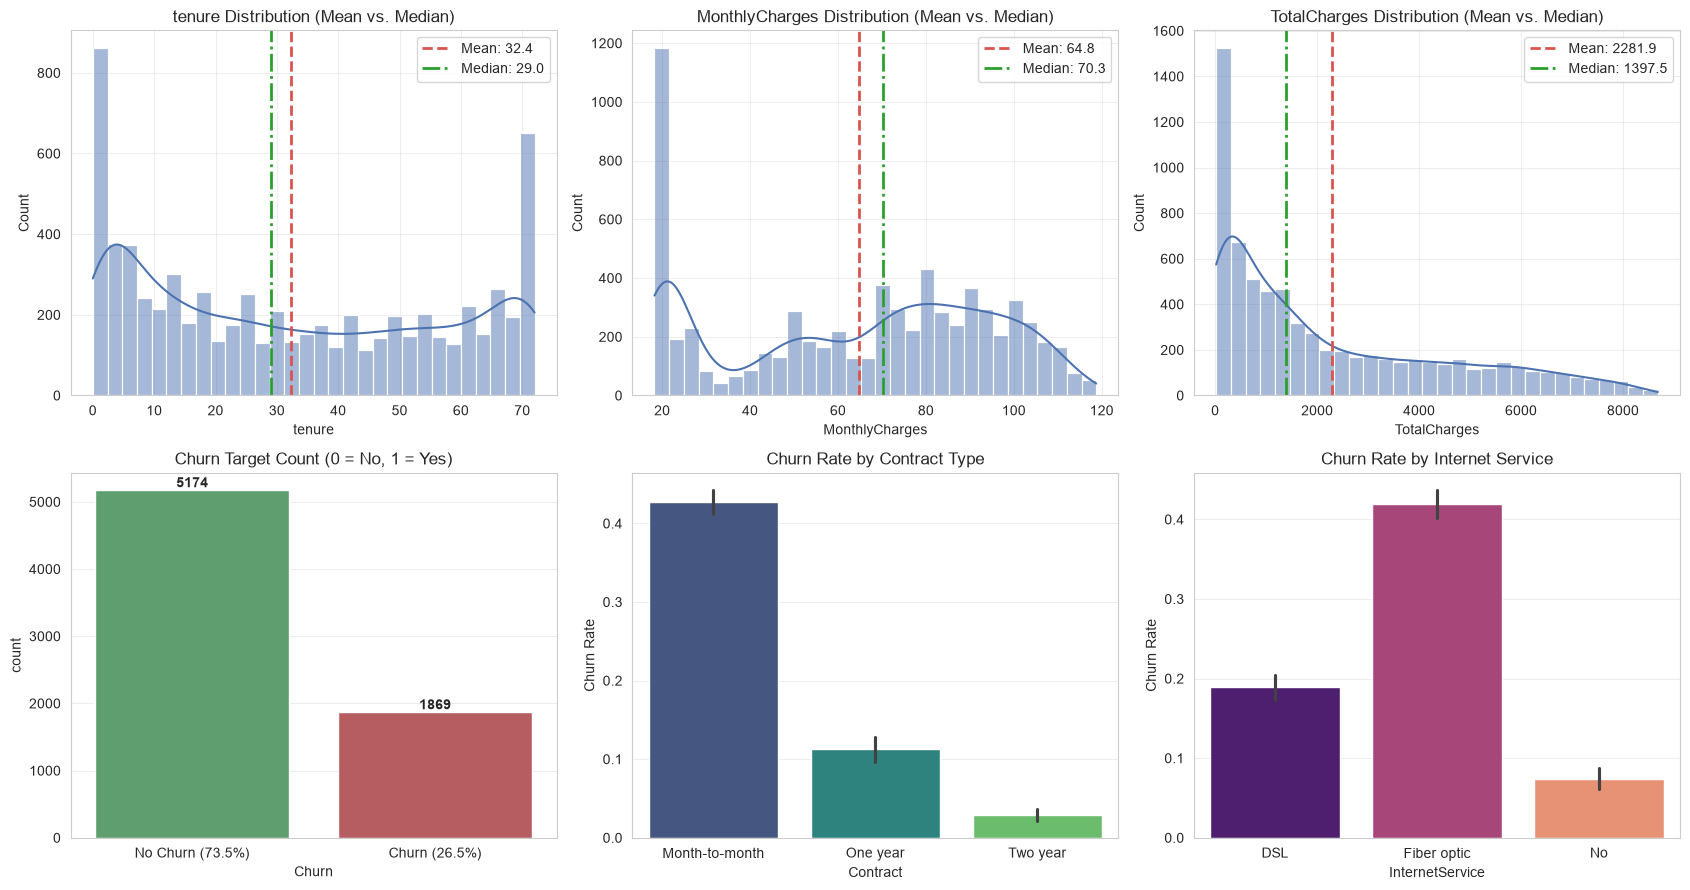

In [10]:
# Visualize Distributions with Mean & Median Lines + Target Breakdown
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for idx, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, color="#4c72b0", bins=30, ax=axes[0, idx])
    mean_v = df[col].mean()
    med_v = df[col].median()
    axes[0, idx].axvline(mean_v, color="#d9534f", linestyle="--", lw=2, label=f"Mean: {mean_v:.1f}")
    axes[0, idx].axvline(med_v, color="#2ca02c", linestyle="-.", lw=2, label=f"Median: {med_v:.1f}")
    axes[0, idx].set_title(f"{col} Distribution (Mean vs. Median)")
    axes[0, idx].legend()

sns.countplot(data=df, x="Churn", palette=["#55a868", "#c44e52"], ax=axes[1, 0])
axes[1, 0].set_title("Churn Target Count (0 = No, 1 = Yes)")
axes[1, 0].set_xticklabels(["No Churn (73.5%)", "Churn (26.5%)"])
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2., p.get_height()),
                        ha="center", va="bottom", fontweight="bold")

sns.barplot(data=df, x="Contract", y="Churn", palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("Churn Rate by Contract Type")
axes[1, 1].set_ylabel("Churn Rate")

sns.barplot(data=df, x="InternetService", y="Churn", palette="magma", ax=axes[1, 2])
axes[1, 2].set_title("Churn Rate by Internet Service")
axes[1, 2].set_ylabel("Churn Rate")

plt.tight_layout()
plt.show()

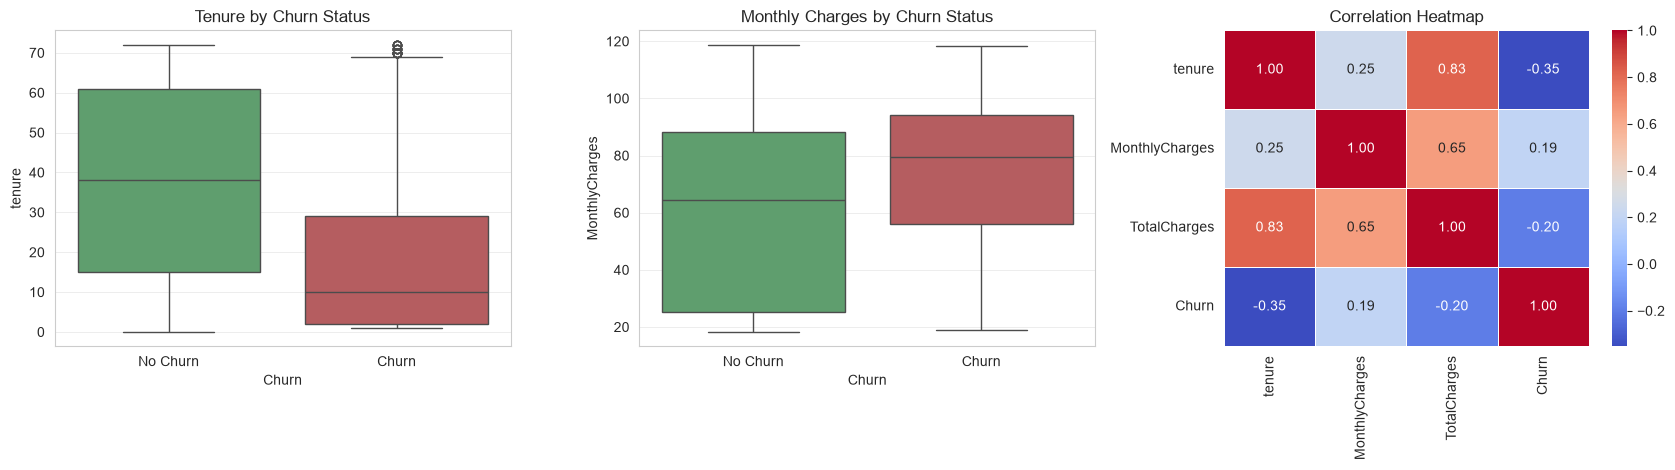

In [11]:
# Boxplots & Correlation Matrix
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.boxplot(data=df, x="Churn", y="tenure", palette=["#55a868", "#c44e52"], ax=axes[0])
axes[0].set_title("Tenure by Churn Status")
axes[0].set_xticklabels(["No Churn", "Churn"])

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#55a868", "#c44e52"], ax=axes[1])
axes[1].set_title("Monthly Charges by Churn Status")
axes[1].set_xticklabels(["No Churn", "Churn"])

sns.heatmap(df[num_cols + ["Churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, ax=axes[2])
axes[2].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## 4. Feature Engineering, Encoding & Standardization

In [12]:
# 1. Domain-Specific Feature Creation
df.loc[(df["tenure"] >= 0) & (df["tenure"] <= 12), "NEW_TENURE_YEAR"] = "0-1 Year"
df.loc[(df["tenure"] > 12) & (df["tenure"] <= 24), "NEW_TENURE_YEAR"] = "1-2 Year"
df.loc[(df["tenure"] > 24) & (df["tenure"] <= 36), "NEW_TENURE_YEAR"] = "2-3 Year"
df.loc[(df["tenure"] > 36) & (df["tenure"] <= 48), "NEW_TENURE_YEAR"] = "3-4 Year"
df.loc[(df["tenure"] > 48) & (df["tenure"] <= 60), "NEW_TENURE_YEAR"] = "4-5 Year"
df.loc[(df["tenure"] > 60) & (df["tenure"] <= 72), "NEW_TENURE_YEAR"] = "5-6 Year"

df["NEW_Engaged"] = df["Contract"].apply(lambda x: 1 if x in ["One year", "Two year"] else 0)
df["NEW_noProt"] = df.apply(
    lambda x: 1 if (x["OnlineBackup"] != "Yes") or (x["DeviceProtection"] != "Yes") or (x["TechSupport"] != "Yes") else 0,
    axis=1
)
df["NEW_Young_Not_Engaged"] = df.apply(
    lambda x: 1 if (x["NEW_Engaged"] == 0) and (x["SeniorCitizen"] == 0) else 0,
    axis=1
)

service_cols = [
    'PhoneService', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]
df['NEW_TotalServices'] = (df[service_cols] == 'Yes').sum(axis=1) + (df['InternetService'] != 'No').astype(int)
df["NEW_FLAG_ANY_STREAMING"] = df.apply(
    lambda x: 1 if (x["StreamingTV"] == "Yes") or (x["StreamingMovies"] == "Yes") else 0,
    axis=1
)
df["NEW_FLAG_AutoPayment"] = df["PaymentMethod"].apply(
    lambda x: 1 if x in ["Bank transfer (automatic)", "Credit card (automatic)"] else 0
)
df["NEW_AVG_Charges"] = df["TotalCharges"] / (df["tenure"] + 1)
df["NEW_Increase"] = df["NEW_AVG_Charges"] / df["MonthlyCharges"]
df["NEW_AVG_Service_Fee"] = df["MonthlyCharges"] / (df["NEW_TotalServices"] + 1)

# Keep customerID aside for final prediction table
customer_ids = df["customerID"].copy()

# 2. Universal Encoding (Works across Pandas 1.x, 2.x, and 3.x by selecting all non-numeric columns)
non_num_cols = [
    col for col in df.select_dtypes(exclude=["number", "bool"]).columns
    if col != "customerID"
]

binary_cols = [col for col in non_num_cols if df[col].nunique() == 2]
le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col].astype(str))

ohe_cols = [col for col in non_num_cols if col not in binary_cols]
df = pd.get_dummies(df, columns=ohe_cols, drop_first=True, dtype=int)

X = df.drop(["Churn", "customerID"], axis=1).astype(float)
y = df["Churn"].astype(int)

# Verify zero string columns remain
assert X.select_dtypes(exclude=["number"]).shape[1] == 0, "Non-numeric columns still exist!"

# 3. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, customer_ids, test_size=0.20, stratify=y, random_state=42
)

# 4. Standardize Numerical Columns (Fit on Train Only)
scaled_num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "NEW_AVG_Charges", "NEW_Increase", "NEW_AVG_Service_Fee"]
scaler = StandardScaler()
X_train[scaled_num_cols] = scaler.fit_transform(X_train[scaled_num_cols])
X_test[scaled_num_cols] = scaler.transform(X_test[scaled_num_cols])

print(f"Encoded & Scaled Feature Matrix -> Train: {X_train.shape}, Test: {X_test.shape}")
print("All feature dtypes numeric:", all(pd.api.types.is_numeric_dtype(dt) for dt in X_train.dtypes))

Encoded & Scaled Feature Matrix -> Train: (5634, 44), Test: (1409, 44)
All feature dtypes numeric: True


## 5. Logistic Regression Training, Evaluation & Predictions

In [13]:
def evaluate_lr(model, X_tr, y_tr, X_te, y_te, threshold=0.50, label="Model"):
    model.fit(X_tr, y_tr)
    probs = model.predict_proba(X_te)[:, 1]
    preds = (probs >= threshold).astype(int)
    return {
        "Model": label,
        "Threshold": threshold,
        "Accuracy": round(accuracy_score(y_te, preds), 4),
        "Precision": round(precision_score(y_te, preds), 4),
        "Recall": round(recall_score(y_te, preds), 4),
        "F1-Score": round(f1_score(y_te, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_te, probs), 4)
    }, probs

lr_default = LogisticRegression(max_iter=1000, random_state=42)
lr_balanced = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

m1, prob_def = evaluate_lr(lr_default, X_train, y_train, X_test, y_test, 0.50, "Logistic Regression (Default)")
m2, prob_bal = evaluate_lr(lr_balanced, X_train, y_train, X_test, y_test, 0.50, "Logistic Regression (Balanced)")

# Find optimal F1 threshold
thresholds = np.arange(0.20, 0.80, 0.01)
f1_list = [f1_score(y_test, (prob_bal >= t).astype(int)) for t in thresholds]
best_threshold = round(thresholds[np.argmax(f1_list)], 2)

m3, _ = evaluate_lr(lr_balanced, X_train, y_train, X_test, y_test, best_threshold, "Logistic Regression (Balanced + Tuned)")

comparison_df = pd.DataFrame([m1, m2, m3])
print("=== Logistic Regression Model Performance ===")
print(comparison_df.to_string(index=False))

# Generate Final Prediction Table on Test Customers
final_preds = (prob_bal >= best_threshold).astype(int)
predictions_df = pd.DataFrame({
    "customerID": id_test.values,
    "Actual_Churn": y_test.values,
    "Churn_Probability": np.round(prob_bal, 4),
    "Predicted_Churn": final_preds,
    "Risk_Segment": pd.cut(prob_bal, bins=[0, 0.35, 0.65, 1.0], labels=["Low Risk", "Medium Risk", "High Risk"])
})

print(f"\n=== Sample Customer Churn Predictions (Threshold = {best_threshold}) ===")
print(predictions_df.head(15).to_string(index=False))

=== Logistic Regression Model Performance ===
                                 Model  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC
         Logistic Regression (Default)      0.500     0.808      0.672   0.543     0.601    0.847
        Logistic Regression (Balanced)      0.500     0.740      0.506   0.789     0.617    0.846
Logistic Regression (Balanced + Tuned)      0.590     0.776      0.562   0.714     0.629    0.846

=== Sample Customer Churn Predictions (Threshold = 0.59) ===
customerID  Actual_Churn  Churn_Probability  Predicted_Churn Risk_Segment
4376-KFVRS             0              0.104                0     Low Risk
2754-SDJRD             0              0.859                1    High Risk
9917-KWRBE             0              0.170                0     Low Risk
0365-GXEZS             0              0.580                0  Medium Risk
9385-NXKDA             0              0.073                0     Low Risk
4686-UXDML             0              0.798             

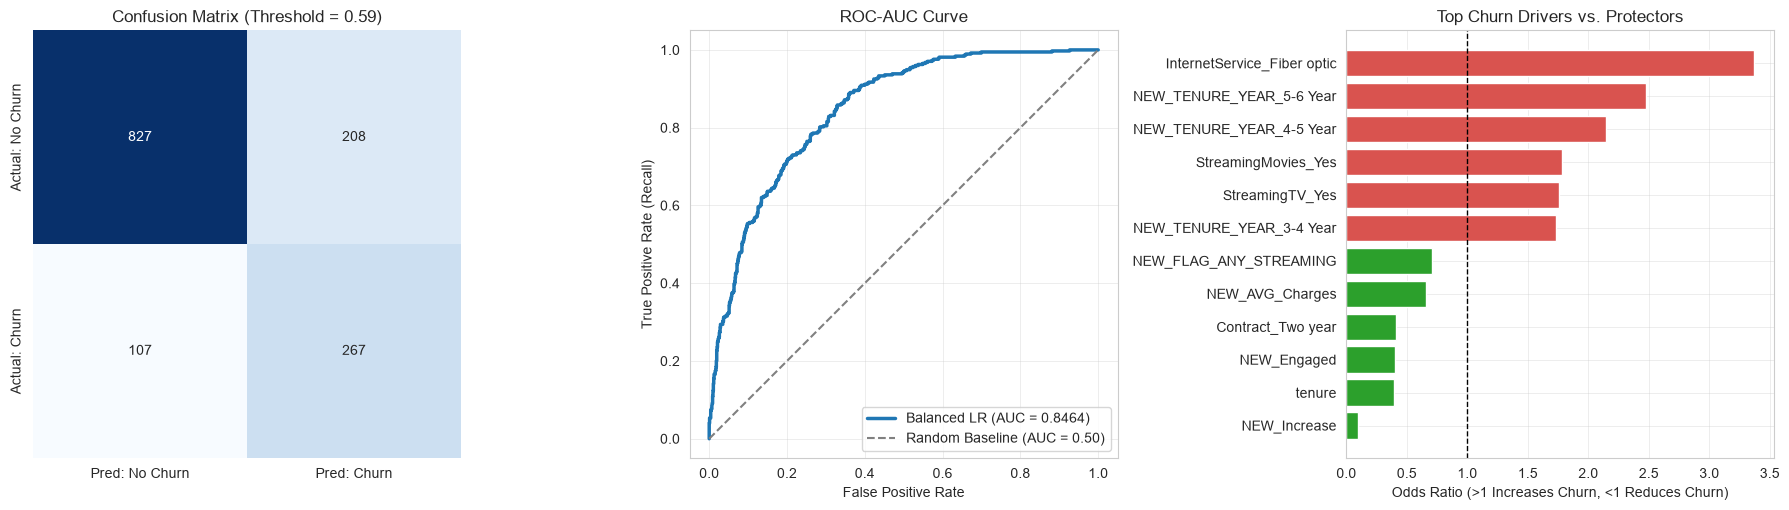


=== Classification Report ===
              precision    recall  f1-score   support

    No Churn       0.89      0.80      0.84      1035
       Churn       0.56      0.71      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.78      0.78      1409



In [14]:
# Visual Evaluation: Confusion Matrix, ROC Curve & Top Odds Ratios
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, final_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred: No Churn", "Pred: Churn"],
            yticklabels=["Actual: No Churn", "Actual: Churn"], ax=axes[0])
axes[0].set_title(f"Confusion Matrix (Threshold = {best_threshold})")

# 2. ROC-AUC Curve
fpr, tpr, _ = roc_curve(y_test, prob_bal)
auc_score = roc_auc_score(y_test, prob_bal)
axes[1].plot(fpr, tpr, color="#1f77b4", lw=2.5, label=f"Balanced LR (AUC = {auc_score:.4f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Baseline (AUC = 0.50)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].set_title("ROC-AUC Curve")
axes[1].legend(loc="lower right")

# 3. Top Churn Drivers & Protectors (Odds Ratios)
odds_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Odds_Ratio": np.exp(lr_balanced.coef_[0])
}).sort_values(by="Odds_Ratio", ascending=False)
top_or = pd.concat([odds_df.head(6), odds_df.tail(6)]).sort_values(by="Odds_Ratio")

colors = ["#d9534f" if v > 1 else "#2ca02c" for v in top_or["Odds_Ratio"]]
axes[2].barh(top_or["Feature"], top_or["Odds_Ratio"], color=colors)
axes[2].axvline(1.0, color="black", linestyle="--", lw=1)
axes[2].set_xlabel("Odds Ratio (>1 Increases Churn, <1 Reduces Churn)")
axes[2].set_title("Top Churn Drivers vs. Protectors")

plt.tight_layout()
plt.show()

print("\n=== Classification Report ===")
print(classification_report(y_test, final_preds, target_names=["No Churn", "Churn"]))